# Machine Learning Midterm - Wine Classification

This notebook covers Sections 1-10 for the Wine dataset. Shared functions are in `utils.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import utils

pd.set_option("display.max_columns", 50)
utils.make_folders()

DATASET = "wine"
display(utils.package_versions())

,package,version
0,python,3.14.3
1,numpy,2.5.4
2,pandas,3.1.1
3,scikit-learn,1.9.1
4,scipy,1.18.1
5,matplotlib,3.11.2
6,seaborn,0.13.2


# 1. Loading the Dataset
## 1.1 Load the dataset from scikit-learn

In [2]:
X, y, class_names = utils.load_data(DATASET)
print("Loaded with load_wine()")

Loaded with load_wine()


### 1.2 Create the data frame (X and y are kept separate)

In [3]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Is the target inside X?", "target" in X.columns)
print("\nFeature names:", list(X.columns))
print("\nTarget labels:", sorted(int(v) for v in y.unique()))
print("Target names:", class_names)
display(X.head())

Shape of X: (178, 13)
Shape of y: (178,)
Is the target inside X? False

Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Target labels: [0, 1, 2]
Target names: ['class_0', 'class_1', 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [4]:
display(utils.class_table(y, class_names))

,label,class_name,n_samples,percent
0,0,class_0,59,33.15
1,1,class_1,71,39.89
2,2,class_2,48,26.97


**Interpretation.** The dataset has 178 samples and 13 numerical chemical features; the target is kept outside X. The class counts are class_0 = 59 (33.1%), class_1 = 71 (39.9%) and class_2 = 48 (27.0%). The imbalance is mild, but stratification and macro averaging are still used. The original labels 0, 1 and 2 are kept.

## 2. Dataset Quality Checks
### 2.1 Missing values and duplicates

In [5]:
missing = utils.missing_table(X)
display(missing)
print("Total missing values:", int(missing["missing_count"].sum()))
print("Duplicate rows:", utils.count_duplicates(X, y))
print("No missing values and no duplicate rows, so no imputation is needed.")

,feature,missing_count
0,alcohol,0
1,malic_acid,0
2,ash,0
3,alcalinity_of_ash,0
4,magnesium,0
5,total_phenols,0
6,flavanoids,0
7,nonflavanoid_phenols,0
8,proanthocyanins,0
9,color_intensity,0


Total missing values: 0
Duplicate rows: 0
No missing values and no duplicate rows, so no imputation is needed.


### 2.2 Potential outliers (IQR rule and |z| > 3) - nothing is removed

In [6]:
outliers = utils.outlier_table(X)
display(outliers)
print("Features with at least one IQR outlier:", int((outliers["n_iqr_outliers"] > 0).sum()), "of", X.shape[1])

,feature,iqr_lower,iqr_upper,n_iqr_outliers,n_abs_z_gt_3
4,magnesium,59.5000,135.5000,4,2
3,alcalinity_of_ash,10.7500,27.9500,4,1
9,color_intensity,-1.2500,10.6700,4,1
1,malic_acid,-0.6175,5.3025,3,1
2,ash,1.6887,3.0788,3,3
8,proanthocyanins,0.2000,3.0000,2,1
10,hue,0.2762,1.6263,1,1
0,alcohol,10.3900,15.6500,0,0
5,total_phenols,0.1563,4.3862,0,0
7,nonflavanoid_phenols,0.0188,0.6888,0,0


Features with at least one IQR outlier: 7 of 13


### 2.3 Data types

In [7]:
display(utils.dtype_table(X))
n_num = X.select_dtypes(include="number").shape[1]
print("Numerical features:", n_num, "| Categorical features:", X.shape[1] - n_num)

,feature,dtype
0,alcohol,float64
1,malic_acid,float64
2,ash,float64
3,alcalinity_of_ash,float64
4,magnesium,float64
5,total_phenols,float64
6,flavanoids,float64
7,nonflavanoid_phenols,float64
8,proanthocyanins,float64
9,color_intensity,float64


Numerical features: 13 | Categorical features: 0


**Interpretation** There are no missing values and no duplicate rows. All 13 features are float64 (13 numerical, 0 categorical). 7 of the 13 features have IQR outliers, but only a few each (at most 4, for `magnesium`, `alcalinity_of_ash` and `color_intensity`), so they are kept. The bigger issue is scale: `proline` ranges from 278 to 1680 and `magnesium` from 70 to 162, while `hue` lies between 0.48 and 1.71. In unscaled Euclidean distance (KNN, K-Means), `proline` therefore dominates. GaussianNB's mean and variance estimates are slightly pulled by the few extreme values. Decision trees are robust because they use thresholds.

## 3. Exploratory Data Analysis (EDA)
Sections 2-3 are descriptive only. They are not used to select features, fit preprocessing or remove samples.
### 3.1 Descriptive statistics

In [8]:
display(utils.describe_features(X))

,mean,median,min,max,std,Q1,Q3
alcohol,13.0006,13.050,11.03,14.83,0.8118,12.3625,13.6775
malic_acid,2.3363,1.865,0.74,5.80,1.1171,1.6025,3.0825
ash,2.3665,2.360,1.36,3.23,0.2743,2.2100,2.5575
alcalinity_of_ash,19.4949,19.500,10.60,30.00,3.3396,17.2000,21.5000
magnesium,99.7416,98.000,70.00,162.00,14.2825,88.0000,107.0000
total_phenols,2.2951,2.355,0.98,3.88,0.6259,1.7425,2.8000
flavanoids,2.0293,2.135,0.34,5.08,0.9989,1.2050,2.8750
nonflavanoid_phenols,0.3619,0.340,0.13,0.66,0.1245,0.2700,0.4375
proanthocyanins,1.5909,1.555,0.41,3.58,0.5724,1.2500,1.9500
color_intensity,5.0581,4.690,1.28,13.00,2.3183,3.2200,6.2000


### 3.2 Class distribution and correlations

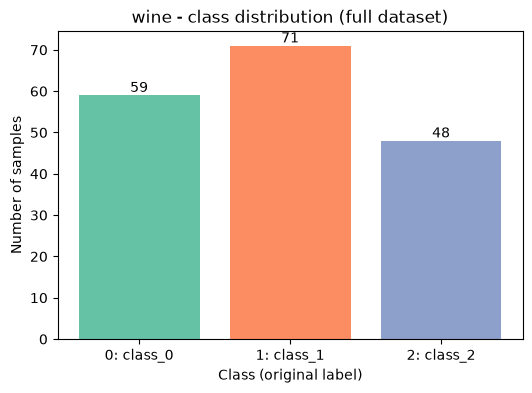

In [9]:
utils.plot_class_distribution(y, class_names, DATASET)

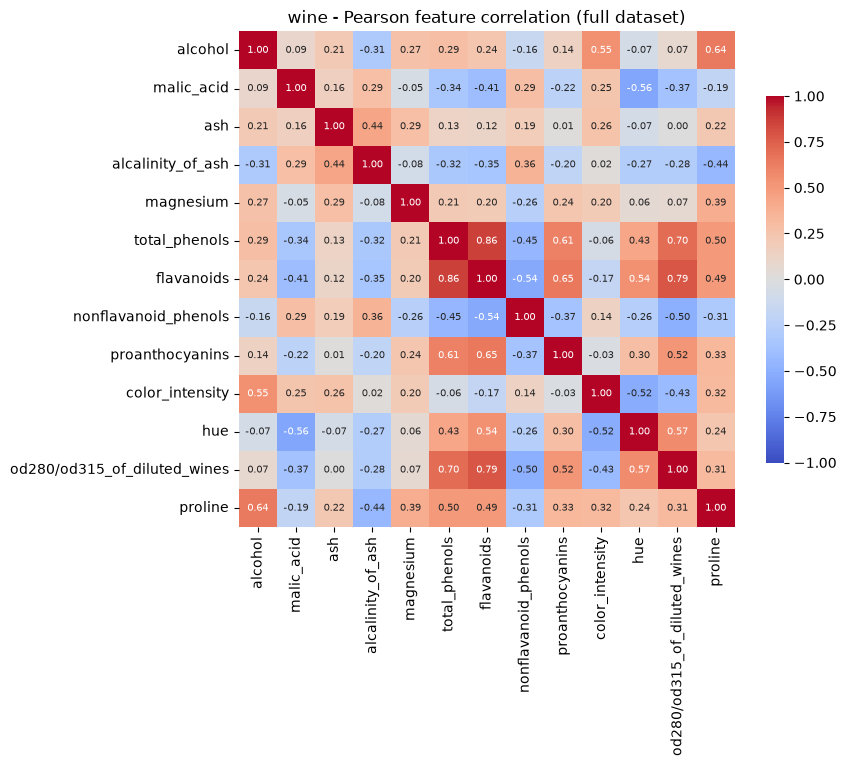

Three strongest unique feature pairs by |Pearson r|:


,feature_1,feature_2,pearson_r,abs_r
0,total_phenols,flavanoids,0.8646,0.8646
1,flavanoids,od280/od315_of_diluted_wines,0.7872,0.7872
2,total_phenols,od280/od315_of_diluted_wines,0.6999,0.6999


In [10]:
corr = utils.plot_corr_heatmap(X, DATASET)
print("Three strongest unique feature pairs by |Pearson r|:")
display(utils.top_corr_pairs(corr, n=3))

### 3.3 Boxplots

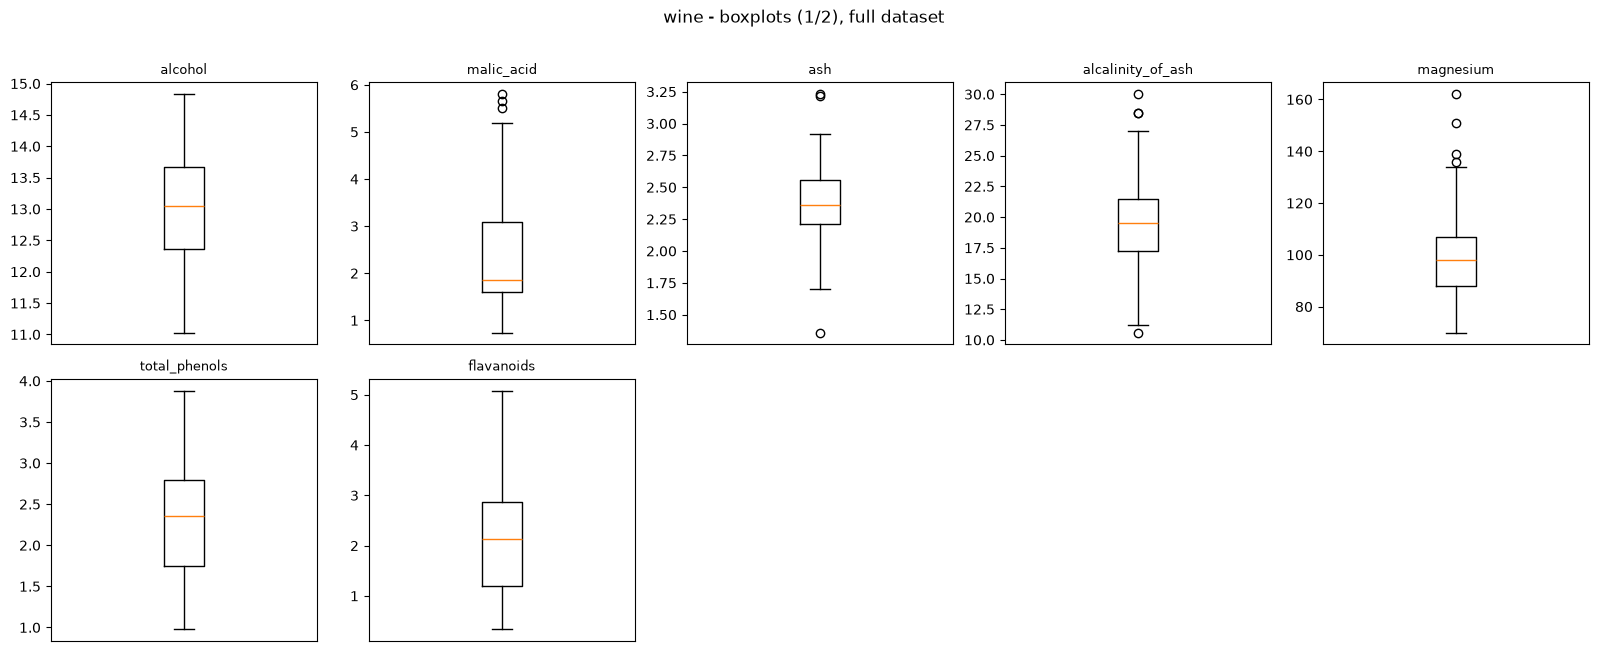

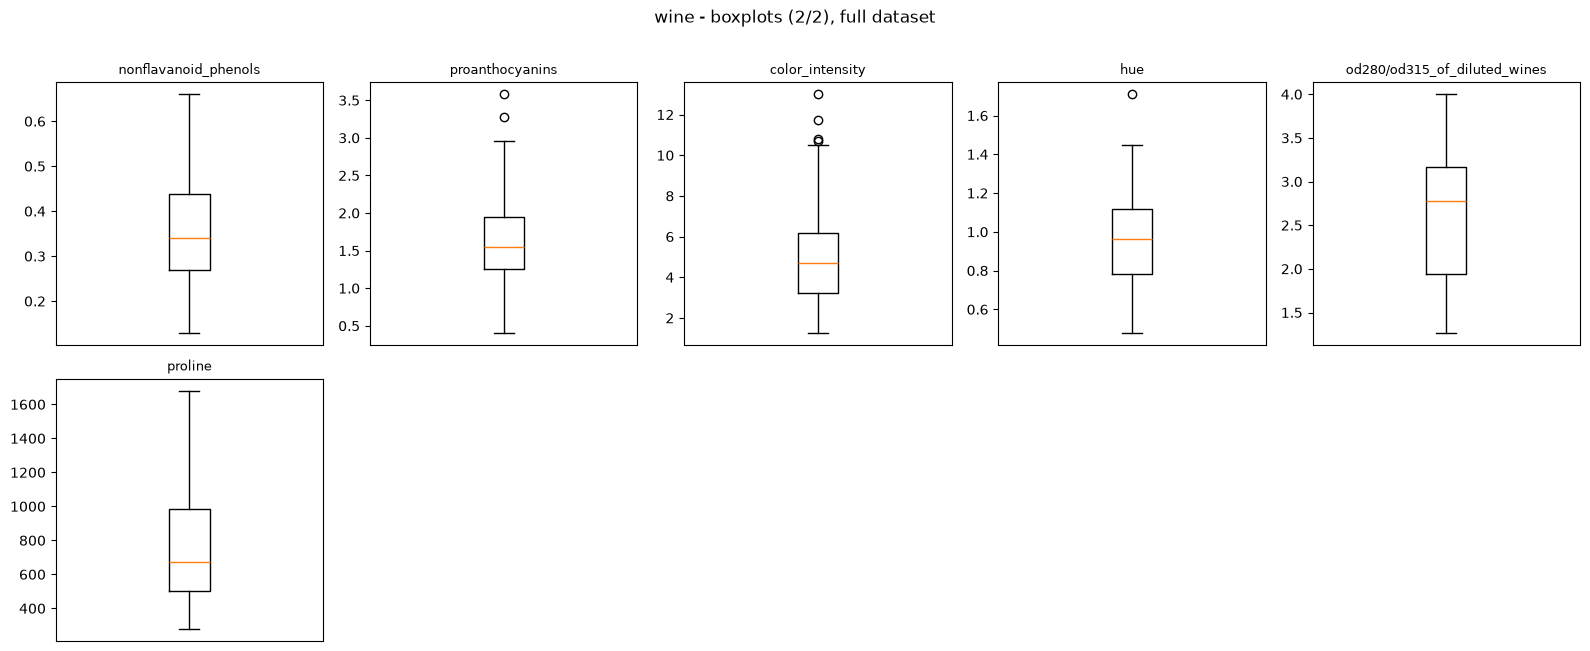

In [11]:
utils.plot_boxplots(X, DATASET, per_figure=7)

**Interpretation.** The features have very different ranges: `proline` has a mean of 746.9 and a standard deviation of 314.9, while `nonflavanoid_phenols` has a mean of 0.36 and a standard deviation of 0.12. `class_1` is the largest class. The three strongest unique correlations are `total_phenols`-`flavanoids` (r = 0.865), `flavanoids`-`od280/od315_of_diluted_wines` (r = 0.787) and `total_phenols`-`od280/od315_of_diluted_wines` (r = 0.700); these phenol-related measurements carry overlapping information. Boxplot observations: (1) `proline` and `magnesium` are on a much larger scale than the other features, and `magnesium` has visible high outliers; (2) `malic_acid` and `color_intensity` are right-skewed (mean > median: 2.34 vs 1.87 and 5.06 vs 4.69).

## 4. Splitting the Dataset
### 4.1 Fixed test set + repeated training/validation split
1. The 20% test set is reserved **once** with `test_size=0.20, stratify=y, random_state=42`.
2. For each seed in [42, 52, 62] the remaining 80% is split with `test_size=0.125`, stratified, `random_state=seed` (0.125 x 80% = 10% of the full dataset).

In [12]:
splits, X_test, y_test = utils.make_splits(X, y)
for seed in utils.SEEDS:
    s = splits[seed]
    print(f"seed {seed}: X_train {s['X_train'].shape}, X_val {s['X_val'].shape}, X_test {X_test.shape}")

seed 42: X_train (124, 13), X_val (18, 13), X_test (36, 13)
seed 52: X_train (124, 13), X_val (18, 13), X_test (36, 13)
seed 62: X_train (124, 13), X_val (18, 13), X_test (36, 13)


### 4.2 Verify the split

In [13]:
print(f"Split summary for {DATASET} (3 subsets x 3 seeds = 9 rows):")
display(utils.split_summary(splits, y_test, len(X), class_names))
display(utils.check_splits(splits, X_test, len(X)))

same_test = all(
    set(X_test.index) == set(X.index) - set(splits[s]["X_train"].index) - set(splits[s]["X_val"].index)
    for s in utils.SEEDS)
print("Test indices identical across all three repetitions:", same_test)

Split summary for wine (3 subsets x 3 seeds = 9 rows):


,seed,subset,n,percent,class_0_class_0,class_1_class_1,class_2_class_2
0,42,train,124,69.66,41,50,33
1,42,validation,18,10.11,6,7,5
2,42,test,36,20.22,12,14,10
3,52,train,124,69.66,41,50,33
4,52,validation,18,10.11,6,7,5
5,52,test,36,20.22,12,14,10
6,62,train,124,69.66,41,50,33
7,62,validation,18,10.11,6,7,5
8,62,test,36,20.22,12,14,10


,seed,train_val_overlap,train_test_overlap,val_test_overlap,total_rows,covers_full_dataset
0,42,0,0,0,178,True
1,52,0,0,0,178,True
2,62,0,0,0,178,True


Test indices identical across all three repetitions: True


In [14]:
idx_table, path = utils.save_split_indices(splits, X_test, DATASET)
show = idx_table[["seed", "subset", "n"]].copy()
show["first_10_indices"] = idx_table["original_row_indices"].str.split().str[:10]
display(show)
print("Full index lists saved to", path)

,seed,subset,n,first_10_indices
0,42,train,124,"[2, 3, 5, 8, 9, 11, 12, 13, 15, 16]"
1,42,validation,18,"[0, 1, 4, 6, 33, 35, 79, 86, 89, 97]"
2,42,test,36,"[7, 10, 14, 18, 20, 22, 28, 38, 42, 48]"
3,52,train,124,"[0, 1, 3, 4, 5, 6, 8, 9, 11, 12]"
4,52,validation,18,"[2, 31, 33, 34, 40, 45, 63, 69, 70, 91]"
5,52,test,36,"[7, 10, 14, 18, 20, 22, 28, 38, 42, 48]"
6,62,train,124,"[0, 1, 3, 4, 5, 6, 8, 11, 12, 13]"
7,62,validation,18,"[2, 9, 15, 25, 27, 29, 67, 68, 101, 107]"
8,62,test,36,"[7, 10, 14, 18, 20, 22, 28, 38, 42, 48]"


Full index lists saved to results\wine_split_indices.csv


**Interpretation.** For every seed the split is 124 / 18 / 36 rows (69.66% / 10.11% / 20.22%); integer rounding moves the percentages slightly away from 70/10/20. Stratification keeps the class counts at 41/50/33 (training), 6/7/5 (validation) and 12/14/10 (testing) for all seeds. The seeds change which rows are in training and validation, but the 36 test rows are identical in all three repetitions. There is no overlap between subsets and the three subsets always add up to 178 rows. Seed 42 is fixed in advance as the run used for the final test evaluation.

## 5. Data Preprocessing and Scaling
### 5.1 Missing values
Section 2 found **no missing values**, so no imputation step is added.
### 5.2 Selected scaler: StandardScaler
StandardScaler transforms every feature to z = (x - mean_train) / std_train. The same scaler type is used for both datasets and all three seeds.
### 5.3 Fit and apply the scaler correctly
A new scaler is fitted per seed on that seed's training features only (3 here, 6 across both datasets). Validation data are only transformed. The test set is transformed only with the seed-42 scaler.

In [15]:
reps, scalers, test_reps = utils.scale_data(splits, X_test)
for seed in utils.SEEDS:
    sc = scalers[seed]
    print(f"seed {seed}: scaler fitted on {int(sc.n_samples_seen_)} training rows; "
          f"first feature mean_train = {sc.mean_[0]:.4f}, std_train = {sc.scale_[0]:.4f}")

Xtr_s, _ = reps[42]["scaled"]
print("\nSeed-42 scaled training data: mean of every column ~ 0 ?",
      np.allclose(Xtr_s.mean().values, 0, atol=1e-9),
      "| std ~ 1 ?", np.allclose(Xtr_s.std(ddof=0).values, 1, atol=1e-9))

seed 42: scaler fitted on 124 training rows; first feature mean_train = 12.9738, std_train = 0.7874
seed 52: scaler fitted on 124 training rows; first feature mean_train = 12.9770, std_train = 0.7987
seed 62: scaler fitted on 124 training rows; first feature mean_train = 12.9483, std_train = 0.8250

Seed-42 scaled training data: mean of every column ~ 0 ? True | std ~ 1 ? True


In [16]:
print("Seed 42 - first five TRAINING rows BEFORE scaling:")
display(reps[42]["unscaled"][0].head())
print("Seed 42 - the same five TRAINING rows AFTER StandardScaler:")
display(reps[42]["scaled"][0].head().round(4))

Seed 42 - first five TRAINING rows BEFORE scaling:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


Seed 42 - the same five TRAINING rows AFTER StandardScaler:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.0175,1.0892,-0.0401,-0.3084,0.4332,-1.3425,-1.3223,0.3527,-1.1176,0.1258,-1.2268,-1.2236,-0.2094
148,0.4397,0.8918,0.0729,0.6094,-0.5057,-0.4910,-1.2599,0.7699,-0.5719,1.5123,-1.8114,-1.4147,-0.2914
116,-1.4654,-0.7720,-1.3968,0.3953,-0.9081,-0.4121,-0.3865,-0.4819,-0.0789,-1.3445,-0.0125,1.0978,-0.8000
122,-0.7033,2.0104,1.3920,2.1391,0.1650,-0.0652,0.1645,0.6030,0.2380,-1.2871,-0.1475,0.7893,-1.2265
115,-2.4687,-0.7344,-0.6054,0.6094,-0.9752,0.3448,0.2061,1.3541,0.7661,-1.3665,3.4052,0.4219,-1.0887


**Interpretation.** StandardScaler was used, the same scaler type as for Breast Cancer. After scaling, each feature has a mean of 0 and a standard deviation of 1 on the training rows. For example, training row 163 has `proline` = 675, which becomes -0.21, and row 115 has `hue` = 1.71, which becomes +3.41 (an unusually high hue). Proline and hue now contribute on the same scale to a distance. The three scalers have slightly different `alcohol` means (12.974, 12.977, 12.948), which shows that each scaler was fitted only on its own training subset.

## 6. Preparing the Two Data Representations
* **Unscaled**: all original features (no imputation needed).
* **Scaled**: the same features and the same row indices after StandardScaler.

Both representations of a seed share exactly the same training and validation rows, so the only difference between them is scaling. No feature selection or dimensionality reduction is applied.

In [17]:
for seed in utils.SEEDS:
    (tr_u, va_u) = reps[seed]["unscaled"]
    (tr_s, va_s) = reps[seed]["scaled"]
    print(f"seed {seed}: same train rows = {tr_u.index.equals(tr_s.index)}, "
          f"same val rows = {va_u.index.equals(va_s.index)}, "
          f"features = {tr_u.shape[1]} / {tr_s.shape[1]}")

print("Test set: same rows =", test_reps["unscaled"].index.equals(test_reps["scaled"].index))

seed 42: same train rows = True, same val rows = True, features = 13 / 13
seed 52: same train rows = True, same val rows = True, features = 13 / 13
seed 62: same train rows = True, same val rows = True, features = 13 / 13
Test set: same rows = True


**Interpretation** For every seed, the unscaled and scaled versions contain exactly the same training and validation rows and all 13 original features. The fixed test set also has the same rows in both versions (scaled with the seed-42 scaler). Any difference between the two representations in Section 7 is therefore caused by scaling only.